# 06 — HOG 128×128, CELL 8×8 | KNN (CS231)

Giữ quy trình của HSV và Color Moments: đọc train/dev → trích xuất feature → thử 120 cấu hình KNN → đánh giá dev → lưu CSV. Chưa đọc test và chưa kết luận HOG tốt hơn các feature trước khi có kết quả.


So với notebook 05, chỉ đổi cell từ 16×16 sang 8×8; giữ nguyên resize, block, hướng, chuẩn hóa và lưới KNN. CSV dùng tiền tố `hog_cell8_`. Train feature chiếm khoảng 386 MiB ở float32; bước KNN cần thêm RAM và thời gian. Chỉ dùng dev để so sánh.


In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import product
import sys

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from IPython.display import display
from skimage.feature import hog

PROJECT_ROOT = Path(r"C:\CS231")
DATA_ROOT = PROJECT_ROOT / "DATA"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.value_metrics import evaluate_classification

## 1. Đọc danh sách ảnh

Chỉ lưu đường dẫn và nhãn, chưa nạp toàn bộ ảnh vào RAM. Khi trích xuất HOG, đọc và xử lý từng ảnh; chỉ giữ lại vector feature.

In [2]:
def load_image_paths_from_folder(folder):
    image_paths = []
    labels = []
    folder = Path(folder)
    class_names = ["10000", "20000", "50000", "100000", "200000", "500000"]

    for class_name in class_names:
        class_folder = folder / class_name
        for img_path in sorted(class_folder.glob("*.png")):
            image_paths.append(img_path)
            labels.append(int(class_name))

    return image_paths, labels, class_names

In [3]:
train_folder = DATA_ROOT / "train"
dev_folder = DATA_ROOT / "dev"

train_paths, train_labels, train_class_names = load_image_paths_from_folder(train_folder)
dev_paths, dev_labels, dev_class_names = load_image_paths_from_folder(dev_folder)

y_train = np.asarray(train_labels, dtype=np.int64)
y_dev = np.asarray(dev_labels, dtype=np.int64)

print("Số ảnh train:", len(train_paths), "| Nhãn:", len(y_train))
print("Số ảnh dev:", len(dev_paths), "| Nhãn:", len(y_dev))
print("Các mệnh giá (VND):", train_class_names)

Số ảnh train: 12494 | Nhãn: 12494
Số ảnh dev: 1564 | Nhãn: 1564
Các mệnh giá (VND): ['10000', '20000', '50000', '100000', '200000', '500000']


## 2. Trích xuất HOG

HOG mô tả hướng thay đổi độ sáng ở từng vùng ảnh, nhằm bổ sung thông tin đường nét mà các feature màu chưa biểu diễn. HOG này dùng ảnh xám nên không giữ màu sắc.

- Resize về **128 × 128** để mọi ảnh có cùng lưới và số chiều. Đây là cấu hình ban đầu để giới hạn chi phí KNN, chưa phải kích thước tối ưu. Resize vuông có thể làm méo tỷ lệ; ở đây chọn cách đơn giản, áp dụng giống nhau cho train/dev. Chỉ resize trong bộ nhớ, không sửa ảnh DATA.
- Mỗi **cell 8 × 8 pixel** gom gradient vào **9 hướng** trong khoảng 0–180 độ. Cell nhỏ hơn chia ảnh thành nhiều vùng hơn, nhưng tăng số chiều và chi phí tính khoảng cách.
- Mỗi **block 2 × 2 cell** được chuẩn hóa **L2-Hys** để giảm ảnh hưởng của thay đổi cường độ sáng. Các block trượt với bước một cell.
- Có 16 × 16 cell, tạo 15 × 15 block. Vector có **15 × 15 × 2 × 2 × 9 = 8.100 chiều**.

Không thêm scaler/PCA để giữ thí nghiệm HOG cơ bản. Chuẩn hóa theo block không làm HOG bất biến hoàn toàn với ánh sáng, xoay hay che khuất. Các tham số được cố định trước khi chạy dev.

Tham khảo: [tài liệu HOG của scikit-image](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.hog).

In [4]:
HOG_SIZE = (128, 128)  # OpenCV dùng thứ tự (width, height)
HOG_ORIENTATIONS = 9
HOG_PIXELS_PER_CELL = (8, 8)
HOG_CELLS_PER_BLOCK = (2, 2)


def extract_hog(image, visualize=False):
    resized = cv2.resize(image, HOG_SIZE, interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(resized, cv2.COLOR_RGB2GRAY)
    return hog(
        gray,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=HOG_PIXELS_PER_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        block_norm="L2-Hys",
        transform_sqrt=False,
        visualize=visualize,
        feature_vector=True,
        channel_axis=None,
    )

In [5]:
sample_bgr = cv2.imread(str(train_paths[0]))
sample_rgb = cv2.cvtColor(sample_bgr, cv2.COLOR_BGR2RGB)
del sample_bgr
sample_hog, sample_hog_image = extract_hog(sample_rgb, visualize=True)

print("Ảnh RGB mẫu:", sample_rgb.shape)
print("HOG shape:", sample_hog.shape)
print("Dtype:", sample_hog.dtype)
print("Min/Max:", sample_hog.min(), sample_hog.max())

Ảnh RGB mẫu: (640, 640, 3)
HOG shape: (8100,)
Dtype: float64
Min/Max: 0.0 0.6325793198471577


## 3. Trực quan hóa HOG của một ảnh

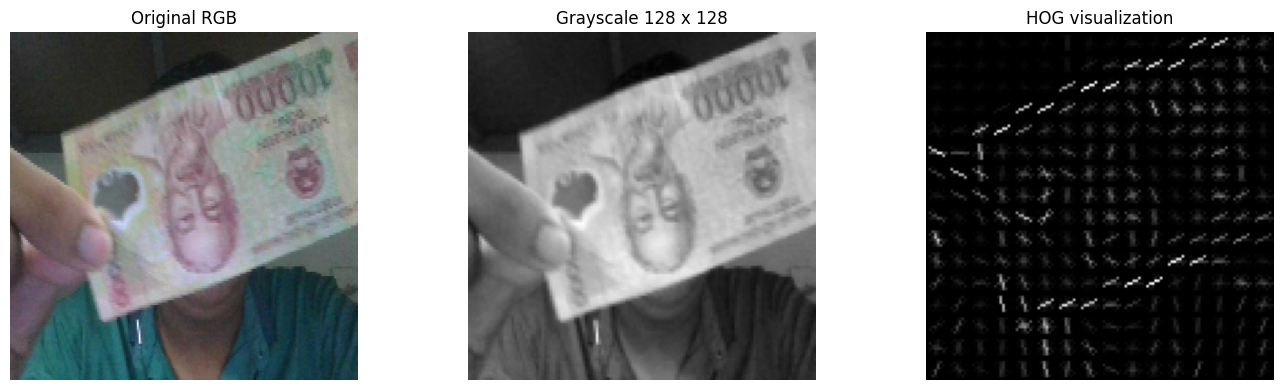

In [6]:
sample_resized = cv2.resize(sample_rgb, HOG_SIZE, interpolation=cv2.INTER_AREA)
sample_gray = cv2.cvtColor(sample_resized, cv2.COLOR_RGB2GRAY)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(sample_rgb)
axes[0].set_title("Original RGB")
axes[1].imshow(sample_gray, cmap="gray")
axes[1].set_title("Grayscale 128 x 128")
axes[2].imshow(sample_hog_image, cmap="gray")
axes[2].set_title("HOG visualization")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Cách đọc hình:** Các đoạn sáng trong hình HOG biểu diễn hướng gradient nổi bật trong mỗi cell; đây không phải ảnh khôi phục từ vector. Quan sát đường viền và họa tiết còn giữ được sau resize. HOG có thông tin vị trí theo lưới nhưng vẫn nhạy với xoay, góc chụp và nền; chưa thể suy ra hiệu quả phân loại từ một ảnh.

## 4. Trích xuất ma trận feature train / dev

In [7]:
def extract_hog_from_paths(image_paths):
    features = np.empty((len(image_paths), len(sample_hog)), dtype=np.float32)

    for i, image_path in enumerate(image_paths):
        image_bgr = cv2.imread(str(image_path))
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        features[i] = extract_hog(image_rgb)
        del image_bgr, image_rgb

    return features


X_train_hog = extract_hog_from_paths(train_paths)
X_dev_hog = extract_hog_from_paths(dev_paths)

print("Train:", X_train_hog.shape, y_train.shape)
print("Dev:  ", X_dev_hog.shape, y_dev.shape)

Train: (12494, 8100) (12494,)
Dev:   (1564, 8100) (1564,)


In [8]:
print("Số chiều HOG:", X_train_hog.shape[1])
print("Dtype:", X_train_hog.dtype)

Số chiều HOG: 8100
Dtype: float32


## 5. Huấn luyện KNN — Grid Search độc lập cho HOG

Giữ đúng lưới của HSV/Color Moments: k từ 1 đến 10, hai cách bỏ phiếu và sáu khoảng cách. Xếp theo Macro-F1 giảm dần, MAE_VND tăng dần, rồi thứ tự thử nếu vẫn hòa. `minkowski` mặc định p=2 tương đương Euclidean; giữ lại để đồng bộ lưới cũ, không xem là một khoảng cách độc lập mới.

HOG có nhiều chiều hơn các feature trước, nên cell này có thể chạy lâu hơn. Chỉ chạy trên CPU; không sử dụng test để chọn cấu hình.

In [9]:
n_neighbors_options = range(1, 11)
weight_options = ["uniform", "distance"]
metric_options = [
    "braycurtis",
    "canberra",
    "correlation",
    "cosine",
    "euclidean",
    "minkowski",
]

results_hog = []

for order, (k, weight, metric) in enumerate(
    product(n_neighbors_options, weight_options, metric_options)
):
    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights=weight,
        metric=metric,
        algorithm="brute"
    )
    knn.fit(X_train_hog, y_train)
    y_pred = knn.predict(X_dev_hog)
    scores = evaluate_classification(y_dev, y_pred)

    results_hog.append({
        "k": k,
        "weights": weight,
        "metric": metric,
        "macro_f1": scores["macro_f1"],
        "mae_vnd": scores["mae_vnd"],
        "accuracy": scores["accuracy"],
        "_order": order,
    })

df_results_hog = (
    pd.DataFrame(results_hog)
    .sort_values(
        ["macro_f1", "mae_vnd", "_order"],
        ascending=[False, True, True]
    )
    .drop(columns="_order")
    .reset_index(drop=True)
)

expected_count = len(n_neighbors_options) * len(weight_options) * len(metric_options)
print("Tổng số cấu hình đã thử:", len(df_results_hog))
display(df_results_hog.head(10))

Tổng số cấu hình đã thử: 120


,k,weights,metric,macro_f1,mae_vnd,accuracy
0,1,uniform,correlation,0.464662,100754.475703,0.469949
1,1,distance,correlation,0.464662,100754.475703,0.469949
2,2,distance,correlation,0.464662,100754.475703,0.469949
3,3,distance,correlation,0.456624,103702.046036,0.462276
4,5,distance,correlation,0.454190,104750.639386,0.459719
5,6,distance,correlation,0.453847,107372.122762,0.459719
6,4,distance,correlation,0.450426,106649.616368,0.455882
7,7,distance,correlation,0.446711,110134.271100,0.453325
8,8,distance,correlation,0.440246,111681.585678,0.447570
9,9,distance,correlation,0.438671,110313.299233,0.447570


In [10]:
best_hog = df_results_hog.iloc[0]
print("Cấu hình HOG tốt nhất trên DEV:")
print(best_hog.to_string())

best_by_metric_hog = (
    df_results_hog
    .drop_duplicates(subset="metric", keep="first")
    .sort_values("macro_f1", ascending=False, kind="stable")
)
print("\nCấu hình tốt nhất của từng distance metric:")
display(best_by_metric_hog[
    ["metric", "k", "weights", "macro_f1", "mae_vnd", "accuracy"]
])

Cấu hình HOG tốt nhất trên DEV:
k                       1
weights           uniform
metric        correlation
macro_f1         0.464662
mae_vnd     100754.475703
accuracy         0.469949

Cấu hình tốt nhất của từng distance metric:


,metric,k,weights,macro_f1,mae_vnd,accuracy
0,correlation,1,uniform,0.464662,100754.475703,0.469949
11,braycurtis,1,uniform,0.437482,103561.381074,0.439898
28,cosine,1,uniform,0.408791,110549.872123,0.410486
32,euclidean,1,uniform,0.405642,112436.061381,0.407289
33,minkowski,1,uniform,0.405642,112436.061381,0.407289
53,canberra,1,uniform,0.398655,119098.465473,0.400895


## 6. Confusion Matrix — cấu hình HOG tốt nhất trên dev

In [11]:
# Tạo lại mô hình từ thông số được chọn bởi Grid Search, không hard-code.
best_knn_hog = KNeighborsClassifier(
    n_neighbors=int(best_hog["k"]),
    weights=str(best_hog["weights"]),
    metric=str(best_hog["metric"]),
    algorithm="brute"
)
best_knn_hog.fit(X_train_hog, y_train)
y_dev_pred_hog = best_knn_hog.predict(X_dev_hog)

hog_scores = evaluate_classification(y_dev, y_dev_pred_hog)
print("DEV Accuracy:", hog_scores["accuracy"])
print("DEV Macro-F1:", hog_scores["macro_f1"])
print("DEV MAE_VND:", hog_scores["mae_vnd"])

DEV Accuracy: 0.46994884910485935
DEV Macro-F1: 0.4646617923799774
DEV MAE_VND: 100754.4757033248


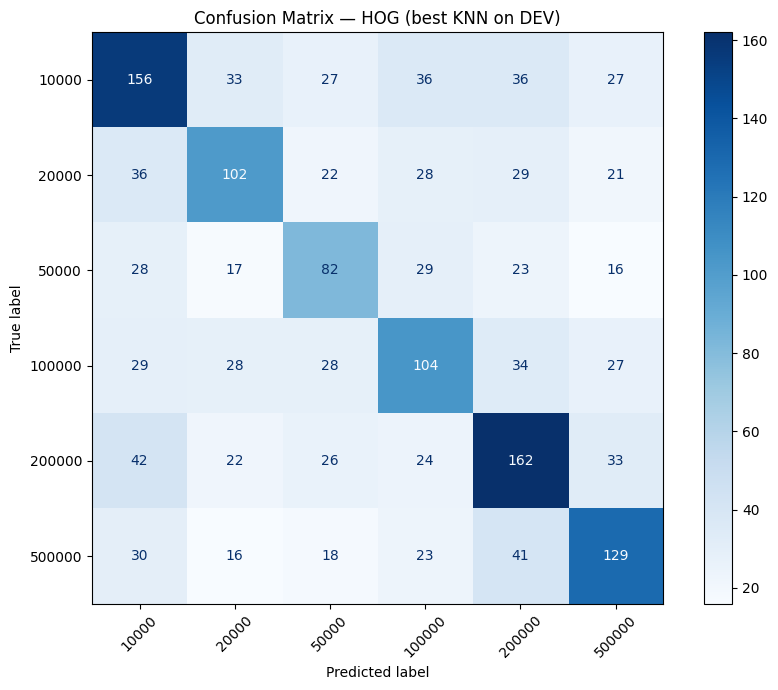

In [12]:
labels = np.sort(np.unique(y_train))
cm_hog = confusion_matrix(y_dev, y_dev_pred_hog, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_hog,
    display_labels=labels
)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
ax.set_title("Confusion Matrix — HOG (best KNN on DEV)")
plt.tight_layout()
plt.show()

In [13]:
report_hog = classification_report(
    y_dev, y_dev_pred_hog,
    labels=labels,
    output_dict=True,
    zero_division=0
)

per_class_hog = pd.DataFrame([
    {
        "denomination_vnd": int(label),
        "precision": report_hog[str(label)]["precision"],
        "recall": report_hog[str(label)]["recall"],
        "f1": report_hog[str(label)]["f1-score"],
        "support": int(report_hog[str(label)]["support"]),
    }
    for label in labels
])

display(per_class_hog)
print(f"Số ảnh đúng: {np.trace(cm_hog)}/{cm_hog.sum()}")

,denomination_vnd,precision,recall,f1,support
0,10000,0.485981,0.495238,0.490566,315
1,20000,0.467890,0.428571,0.447368,238
2,50000,0.403941,0.420513,0.412060,195
3,100000,0.426230,0.416000,0.421053,250
4,200000,0.498462,0.524272,0.511041,309
5,500000,0.509881,0.501946,0.505882,257


Số ảnh đúng: 735/1564


In [14]:
error_pairs_hog = []
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        errors_ij = int(cm_hog[i, j])
        errors_ji = int(cm_hog[j, i])
        error_pairs_hog.append({
            "pair": f"{labels[i]} ↔ {labels[j]}",
            "true_i_pred_j": errors_ij,
            "true_j_pred_i": errors_ji,
            "total_errors": errors_ij + errors_ji,
        })

df_error_pairs_hog = (
    pd.DataFrame(error_pairs_hog)
    .sort_values("total_errors", ascending=False, kind="stable")
)
print("Top 5 cặp mệnh giá nhầm nhiều nhất:")
display(df_error_pairs_hog.head(5))

Top 5 cặp mệnh giá nhầm nhiều nhất:


,pair,true_i_pred_j,true_j_pred_i,total_errors
3,10000 ↔ 200000,36,42,78
14,200000 ↔ 500000,33,41,74
0,10000 ↔ 20000,33,36,69
2,10000 ↔ 100000,36,29,65
12,100000 ↔ 200000,34,24,58


## 7. Lưu kết quả để so sánh 4 feature

In [15]:
# Dùng đường dẫn tuyệt đối đến thư mục KNN để không phụ thuộc cwd của Jupyter.
output_dir = PROJECT_ROOT / "src" / "KNN" / "results"
output_dir.mkdir(parents=True, exist_ok=True)

summary_hog = pd.DataFrame([{
    "feature": "HOG gray 128x128, cell8, block2, orientations9",
    "feature_dim": int(X_train_hog.shape[1]),
    "k": int(best_hog["k"]),
    "weights": str(best_hog["weights"]),
    "metric": str(best_hog["metric"]),
    "macro_f1": float(best_hog["macro_f1"]),
    "mae_vnd": float(best_hog["mae_vnd"]),
    "accuracy": float(best_hog["accuracy"]),
}])

df_results_hog.to_csv(output_dir / "hog_cell8_knn_grid_dev.csv", index=False)
summary_hog.to_csv(output_dir / "hog_cell8_best_dev.csv", index=False)
pd.DataFrame(cm_hog, index=labels, columns=labels).to_csv(
    output_dir / "hog_cell8_confusion_matrix_dev.csv"
)
per_class_hog.to_csv(output_dir / "hog_cell8_per_class_dev.csv", index=False)
df_error_pairs_hog.to_csv(output_dir / "hog_cell8_error_pairs_dev.csv", index=False)

print("Đã lưu kết quả vào:", output_dir)
display(summary_hog)

Đã lưu kết quả vào: C:\CS231\src\KNN\results


,feature,feature_dim,k,weights,metric,macro_f1,mae_vnd,accuracy
0,"HOG gray 128x128, cell8, block2, orientations9",8100,1,uniform,correlation,0.464662,100754.475703,0.469949
